# Exploring Data

In [2]:
# %pip install praw
import praw

In [6]:
# %pip install dotenv
from dotenv import load_dotenv
import os

load_dotenv()

REDDIT_CLIENT_ID = os.getenv("REDDIT_CLIENT_ID")
REDDIT_CLIENT_SECRET = os.getenv("REDDIT_CLIENT_SECRET")

In [8]:
reddit = praw.Reddit(
    client_id=REDDIT_CLIENT_ID,
    client_secret=REDDIT_CLIENT_SECRET,
    user_agent="minimal_script/0.1",
)

## Identifying Subreddits of Interest (SOIs)

In [16]:
SORT_OPTIONS = ["relevance", "hot", "top", "new", "comments"]
TIME_FILTERS = ["all", "year", "month", "week", "day", "hour"]

In [62]:
SEARCH_TERM = "resume"
subs = reddit.subreddits.search(SEARCH_TERM, limit=100)

In [63]:
sub_dict = {"subreddit_name": [], "subscribers": [], "created_at": []}
for sub in subs:
    sub_dict["subreddit_name"].append(sub.display_name)
    sub_dict["subscribers"].append(sub.subscribers)
    sub_dict["created_at"].append(sub.created_utc)

In [65]:
import pandas as pd

subs_df = pd.DataFrame(sub_dict)

In [67]:
# subs_df.to_csv("subs_df_snapshot_11_11_2026.csv", index=False)

In [68]:
subs_df.sort_values(by="subscribers", ascending=False)

,subreddit_name,subscribers,created_at
49,funny,67653694,1.201243e+09
20,AskReddit,60115396,1.201233e+09
24,worldnews,47703084,1.201231e+09
77,Showerthoughts,34210417,1.318973e+09
59,news,31611803,1.201244e+09
...,...,...,...
96,optimizedcv,25,1.743981e+09
40,ResumeFeedback,19,1.708301e+09
67,ActualResumeHelp,17,1.782882e+09
53,BestResume,16,1.759677e+09


In [ ]:
mentions_resume = subs_df["subreddit_name"].str.contains("resume", case=False)

In [77]:
mentions_resume.value_counts()

subreddit_name
False    53
True     47
Name: count, dtype: int64

In [ ]:
subs_df[mentions_resume].sort_values(by="subscribers", ascending=False).describe()

,subscribers,created_at
count,4.700000e+01,4.700000e+01
mean,3.877779e+04,1.629791e+09
std,1.945268e+05,1.573884e+08
min,1.100000e+01,1.237482e+09
25%,1.215000e+02,1.559029e+09
50%,1.091000e+03,1.709235e+09
75%,7.126500e+03,1.751881e+09
max,1.327424e+06,1.790754e+09


In [90]:
MEDIAN_RELEVANT_SUBCOUNT = 1091
is_relevant_size = subs_df["subscribers"] > MEDIAN_RELEVANT_SUBCOUNT

In [141]:
filtered_df = subs_df[
    is_relevant_size
    & mentions_resume
].sort_values(by="subscribers", ascending=False)

In [142]:
# filtered_df.to_csv("relevant_subs_cohort_11_11_2026.csv", index=False)

In [143]:
filtered_df.describe()

,subscribers,created_at
count,2.300000e+01,2.300000e+01
mean,7.897322e+04,1.573029e+09
std,2.753424e+05,1.917792e+08
min,1.458000e+03,1.237482e+09
25%,3.632000e+03,1.414752e+09
50%,7.172000e+03,1.664371e+09
75%,2.234050e+04,1.746024e+09
max,1.327424e+06,1.790754e+09


In [144]:
BOTTOM_25_CUTOFF = filtered_df["subscribers"].quantile(0.25)

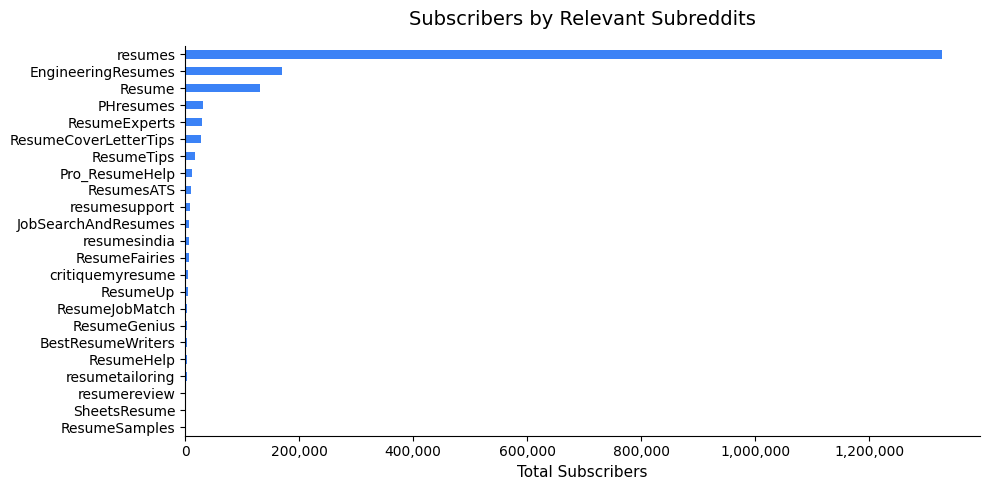

In [149]:
import matplotlib.ticker as ticker
import matplotlib.pyplot as plt

# Sort ascending so largest is on top
ax = (
    filtered_df.sort_values(by="subscribers", ascending=True)
    .plot.barh(x="subreddit_name", y="subscribers", figsize=(10, 5), color="#3b82f6", legend=False)
)

ax.set_title("Subscribers by Relevant Subreddits", fontsize=14, pad=15)
ax.set_xlabel("Total Subscribers", fontsize=11)
ax.set_ylabel("")

# Format x-axis with comma separators (e.g. 500,000 instead of 500000)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}"))

# Remove chart borders for a modern look
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [153]:
relevant_subreddits = set(filtered_df["subreddit_name"].tolist())

In [160]:
import time
import requests
import pandas as pd
from datetime import datetime, timedelta

def scrape_historical_reddit(subreddit: str, days_back: int = 180, max_posts: int = 300) -> pd.DataFrame:
    """
    Fetches historical submissions from Arctic Shift without hitting Reddit's 1000-post limit.
    """
    cutoff_timestamp = int((datetime.now() - timedelta(days=days_back)).timestamp())
    current_before = int(time.time())
    
    collected_posts = []
    
    print(f"[*] Scraping r/{subreddit} back to {datetime.fromtimestamp(cutoff_timestamp).strftime('%Y-%m-%d')}...")

    while current_before > cutoff_timestamp and (max_posts is None or len(collected_posts) < max_posts):
        # Using Arctic Shift endpoint
        url = (
            f"https://arctic-shift.photon-reddit.com/api/posts/search"
            f"?subreddit={subreddit}&limit=100&before={current_before}"
        )
        
        try:
            res = requests.get(url, timeout=15)
            if res.status_code != 200:
                print(f"[!] Server returned {res.status_code}, pausing 3s...")
                time.sleep(3)
                continue
                
            data = res.json().get("data", [])
            if not data:
                print("[*] No more older posts found.")
                break

            for post in data:
                created = post.get("created_utc", 0)
                if created < cutoff_timestamp:
                    break
                
                collected_posts.append({
                    "id": post.get("id"),
                    "subreddit": subreddit,
                    "title": post.get("title"),
                    "selftext": post.get("selftext"),
                    "url": post.get("url"),
                    "score": post.get("score"),
                    "num_comments": post.get("num_comments"),
                    "flair": post.get("link_flair_text"),
                    "created_utc": created,
                })

            # Update pagination cursor to the oldest post in this batch
            current_before = data[-1]["created_utc"]
            print(f"  -> Collected {len(collected_posts)} posts (Reached: {datetime.fromtimestamp(current_before).strftime('%Y-%m-%d')})")
            
            # 1 second pause to be polite to the server
            time.sleep(1)

        except Exception as e:
            print(f"[!] Error: {e}, retrying in 2s...")
            time.sleep(2)

    return pd.DataFrame(collected_posts)

In [161]:
# Example: Get posts from the past 180 days (or 5 * 365 for 5 years)
df_historical = scrape_historical_reddit(subreddit="resumes", days_back=180, max_posts=None)
df_historical.head()

[*] Scraping r/resumes back to 2026-05-15...
  -> Collected 100 posts (Reached: 2026-11-08)
  -> Collected 200 posts (Reached: 2026-11-05)
  -> Collected 300 posts (Reached: 2026-11-03)
  -> Collected 400 posts (Reached: 2026-10-31)
[!] Server returned 422, pausing 3s...
  -> Collected 500 posts (Reached: 2026-10-28)
[!] Server returned 422, pausing 3s...
[!] Server returned 422, pausing 3s...
  -> Collected 600 posts (Reached: 2026-10-27)
  -> Collected 700 posts (Reached: 2026-10-23)
  -> Collected 800 posts (Reached: 2026-10-22)
  -> Collected 900 posts (Reached: 2026-10-20)
  -> Collected 1000 posts (Reached: 2026-10-18)
[!] Server returned 422, pausing 3s...
  -> Collected 1100 posts (Reached: 2026-10-15)
  -> Collected 1200 posts (Reached: 2026-10-12)
  -> Collected 1300 posts (Reached: 2026-10-10)
[!] Server returned 422, pausing 3s...
  -> Collected 1400 posts (Reached: 2026-10-08)
  -> Collected 1500 posts (Reached: 2026-10-06)
  -> Collected 1600 posts (Reached: 2026-10-05)
 

,id,subreddit,title,selftext,url,score,num_comments,flair,created_utc
0,1xt9jpc,resumes,Need help with resume,[removed],https://i.redd.it/vh1qn9or5x0i1.png,1,1,Discussion,1794374969
1,1xt97ss,resumes,Seeking resume advice,[removed],https://www.reddit.com/gallery/1xt97ss,1,1,Finance/Banking,1794373876
2,1xt8vkm,resumes,"[2 YOE(internships), student, OSINT, Canada] p...",,https://i.redd.it/1wwgfbvkzw0i1.jpeg,1,1,Technology/Software/IT,1794372796
3,1xt8dh5,resumes,"[0-1 years, Soon Graduating, SDE-1, Remote]",,https://i.redd.it/jt3ydwrw2u0i1.png,1,1,Technology/Software/IT,1794371139
4,1xt86wb,resumes,Is my resume okay for an film/media internship...,[removed],https://i.redd.it/x9q4wb3hsw0i1.png,1,1,Creative/Media,1794370556


In [154]:
relevant_subreddits

{'BestResumeWriters',
 'EngineeringResumes',
 'JobSearchAndResumes',
 'PHresumes',
 'Pro_ResumeHelp',
 'Resume',
 'ResumeCoverLetterTips',
 'ResumeExperts',
 'ResumeFairies',
 'ResumeGenius',
 'ResumeHelp',
 'ResumeJobMatch',
 'ResumeSamples',
 'ResumeTips',
 'ResumeUp',
 'ResumesATS',
 'SheetsResume',
 'critiquemyresume',
 'resumereview',
 'resumes',
 'resumesindia',
 'resumesupport',
 'resumetailoring'}

In [1]:
# df_historical.to_csv("resumes_historical.csv", index=False)